# Miami smelter: six-day decoding and quality review

**1–6 January 2016 • Collection 002 • local files only**

This notebook checks physical-value decoding, quality flags, missing data and gap-filled reference values before extending processing to the full archive. It reads raw Zarr stores and supplemental QA from the retained monthly NetCDF files. It makes no downloads and does not change either archive.

Select **EI-Nightlights (.venv)**, then **Run All**. Saved outputs are included so you can also review the results without running cells.

In [1]:
import sys
import importlib.util
from pathlib import Path
print('Python:', sys.executable)
missing = [name for name in ['rioxarray', 'xarray', 'numpy', 'pandas', 'matplotlib'] if importlib.util.find_spec(name) is None]
if missing:
    raise RuntimeError('Missing packages: ' + ', '.join(missing) + '. Select EI-Nightlights (.venv), restart, and Run All.')
if not Path('data/miami_zarr').is_dir():
    raise RuntimeError('Run this notebook from the EI-Nightlights project directory.')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from process_viirs_preview import load_preview, plot_preview, export_preview, REASONS, GAP
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 60)
START, END = '2016-01-01', '2016-01-06'

Python: C:\Users\zayed\OneDrive\Desktop\Earth-i\EI-Nightlights\.venv\Scripts\python.exe


## 1. Load and align the small sample

Time and pixel coordinates must match exactly between A1 and A2. Supplemental QA must match the AOI hash, pixel coordinates and source filenames. No resampling or temporal interpolation is performed. There are eight pixels in the bounding window; seven intersect the provisional OSM AOI.

In [2]:
samples, supplemental, processed, audit, packing, daily = load_preview(START, END)
pd.DataFrame([{'product': product, 'days': ds.sizes['time'], 'rows': ds.sizes['y'], 'columns': ds.sizes['x'], 'intersecting_pixels': int(ds.aoi_intersects_pixel.sum()), 'source_days': int(ds.source_available.sum()), 'CRS': str(ds.rio.crs)} for product, ds in samples.items()])

,product,days,rows,columns,intersecting_pixels,source_days,CRS
0,VNP46A1,6,2,4,7,6,EPSG:4326
1,VNP46A2,6,2,4,7,6,EPSG:4326


## 2. Convert packed values to physical units

Check fills and valid ranges **in the native values first**, then apply `physical = raw × scale_factor + offset`. Metadata are read separately for each date and band. Missing scale/offset means identity. In these Collection 2 files, the radiance arrays are already in nW cm⁻² sr⁻¹: applying Collection 1's factor of 0.1 again would be incorrect.

M13 and M15 are **brightness temperatures in kelvin**, not direct furnace or smelter surface temperatures. A VIIRS pixel contains a mixture of surfaces.

In [3]:
packing[['product','date','band','raw_dtype','scale','offset','units']]

,product,date,band,raw_dtype,scale,offset,units
0,VNP46A1,2016-01-01,BrightnessTemperature_M13,uint16,0.0025,203.0,Kelvins
1,VNP46A1,2016-01-01,BrightnessTemperature_M15,uint16,0.0041,111.0,Kelvins
2,VNP46A1,2016-01-01,DNB_At_Sensor_Radiance,float32,1.0000,0.0,nW/(cm2 sr)
3,VNP46A1,2016-01-02,BrightnessTemperature_M13,uint16,0.0025,203.0,Kelvins
4,VNP46A1,2016-01-02,BrightnessTemperature_M15,uint16,0.0041,111.0,Kelvins
5,VNP46A1,2016-01-02,DNB_At_Sensor_Radiance,float32,1.0000,0.0,nW/(cm2 sr)
6,VNP46A1,2016-01-03,BrightnessTemperature_M13,uint16,0.0025,203.0,Kelvins
7,VNP46A1,2016-01-03,BrightnessTemperature_M15,uint16,0.0041,111.0,Kelvins
8,VNP46A1,2016-01-03,DNB_At_Sensor_Radiance,float32,1.0000,0.0,nW/(cm2 sr)
9,VNP46A1,2016-01-04,BrightnessTemperature_M13,uint16,0.0025,203.0,Kelvins


In [4]:
# One intersecting pixel, preserved through every step.
# row=0, column=2 is near the reference location, not a confirmed furnace pixel.
audit[(audit.row == 0) & (audit.column == 2)][['product','date','band','raw','decoded','screened','reasons']].reset_index(drop=True)

,product,date,band,raw,decoded,screened,reasons
0,VNP46A1,2016-01-01,BrightnessTemperature_M13,27105.000000,270.762498,270.762498,retained_current
1,VNP46A1,2016-01-01,BrightnessTemperature_M15,39007.000000,270.928701,270.928701,retained_current
2,VNP46A1,2016-01-01,DNB_At_Sensor_Radiance,45.356297,45.356297,45.356297,retained_current
3,VNP46A1,2016-01-02,BrightnessTemperature_M13,27898.000000,272.744998,272.744998,retained_current
4,VNP46A1,2016-01-02,BrightnessTemperature_M15,39531.000000,273.077101,273.077101,retained_current
5,VNP46A1,2016-01-02,DNB_At_Sensor_Radiance,62.871613,62.871613,62.871613,retained_current
6,VNP46A1,2016-01-03,BrightnessTemperature_M13,27222.000000,271.054998,271.054998,retained_current
7,VNP46A1,2016-01-03,BrightnessTemperature_M15,39384.000000,272.474401,272.474401,retained_current
8,VNP46A1,2016-01-03,DNB_At_Sensor_Radiance,60.896866,60.896866,60.896866,retained_current
9,VNP46A1,2016-01-04,BrightnessTemperature_M13,13224.000000,236.059999,NaN,not_confident_clear


## 3. Decode cloud flags for each product separately

Cloud confidence codes: 0 = confident clear, 1 = probably clear, 2 = probably cloudy, 3 = confident cloudy. Cloud-mask quality codes range from 0 (poor) to 3 (high). A missing/fill cloud mask is represented as −1 in decoded fields; it is never interpreted as a cloudy observation.

The proposed **conservative demonstration policy** retains current observations only when: night, confident clear, cloud-mask quality medium/high, no shadow, cirrus, snow/ice, aurora or lunar eclipse, and the relevant native band-quality flag is zero. A2 also requires a valid snow-free `Snow_Flag`. These are explicit analysis choices, not a claim that NASA requires this exact combination for every application.

Additional QA comes from the already downloaded archive: A1 `QF_DNB`, `QF_VIIRS_M13`, `QF_VIIRS_M15`; A2 `Mandatory_Quality_Flag`, `Snow_Flag`, `Latest_High_Quality_Retrieval`. Collection 2 mandatory flag 0 is high quality; nonzero codes are not retained here. Do not use Collection 1's meaning of flag 1.

In [5]:
# Identical raw cloud-mask numbers are decoded independently in A1 and A2.
cloud_review = audit[audit.inside_aoi].drop_duplicates(['product','date','row','column']).copy()
cloud_review['binary_16_bits'] = cloud_review.raw_cloud_mask.map(lambda value: format(value, '016b'))
cloud_review[['product','date','row','column','raw_cloud_mask','binary_16_bits','day','cloud_quality','cloud_confidence','shadow','cirrus','snow_ice','aurora','lunar_eclipse']].reset_index(drop=True)

,product,date,row,column,raw_cloud_mask,binary_16_bits,day,cloud_quality,cloud_confidence,shadow,cirrus,snow_ice,aurora,lunar_eclipse
0,VNP46A1,2016-01-01,0,1,226,0000000011100010,0,2,3,0,0,0,0,0
1,VNP46A1,2016-01-01,0,2,34,0000000000100010,0,2,0,0,0,0,0,0
2,VNP46A1,2016-01-01,0,3,34,0000000000100010,0,2,0,0,0,0,0,0
3,VNP46A1,2016-01-01,1,0,226,0000000011100010,0,2,3,0,0,0,0,0
4,VNP46A1,2016-01-01,1,1,226,0000000011100010,0,2,3,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,VNP46A2,2016-01-06,0,3,738,0000001011100010,0,2,3,0,1,0,0,0
80,VNP46A2,2016-01-06,1,0,738,0000001011100010,0,2,3,0,1,0,0,0
81,VNP46A2,2016-01-06,1,1,738,0000001011100010,0,2,3,0,1,0,0,0
82,VNP46A2,2016-01-06,1,2,738,0000001011100010,0,2,3,0,1,0,0,0


## 4. Explain every exclusion

`pixel_audit.csv` retains all raw, decoded and screened values, cloud fields and exclusion reasons. Exclusion flags can overlap: a pixel can be both cloudy and cirrus-affected. Missing data remain missing, and a valid zero radiance remains zero. The bounding-window pixel outside the AOI is excluded from summaries.

In [6]:
counts = []
current = audit[audit.inside_aoi & (audit.band != GAP)]
for (product, band), group in current.groupby(['product','band']):
    for bit, reason in REASONS.items():
        count = int(((group.reason_flags.astype('uint16') & bit) != 0).sum())
        if count:
            counts.append({'product': product, 'band': band, 'reason': reason, 'pixel_dates': count})
pd.DataFrame(counts)

,product,band,reason,pixel_dates
0,VNP46A1,BrightnessTemperature_M13,not_confident_clear,25
1,VNP46A1,BrightnessTemperature_M13,cirrus,14
2,VNP46A1,BrightnessTemperature_M15,not_confident_clear,25
3,VNP46A1,BrightnessTemperature_M15,cirrus,14
4,VNP46A1,DNB_At_Sensor_Radiance,not_confident_clear,25
5,VNP46A1,DNB_At_Sensor_Radiance,cirrus,14
6,VNP46A2,DNB_BRDF-Corrected_NTL,fill_or_nonfinite,25
7,VNP46A2,DNB_BRDF-Corrected_NTL,not_confident_clear,25
8,VNP46A2,DNB_BRDF-Corrected_NTL,cirrus,14
9,VNP46A2,DNB_BRDF-Corrected_NTL,band_quality_flag_not_zero,1


## 5. Keep gap-filled nightlights separate

The gap-filled layer is a reference series, not evidence of a fresh observation on every date. Do not filter it using the current day's weather and then call the surviving value a current measurement. NASA's latest-high-quality-retrieval age is shown alongside it; no exact acquisition date is inferred here.

Current corrected NTL stays missing on 4–6 January. The reference values remain available and some repeat as retrieval age increases. The notebook never substitutes those values into the current series.

In [7]:
reference = audit[(audit.band == GAP) & audit.inside_aoi]
reference.groupby('date').agg(available_pixels=('reference_available','sum'), minimum_retrieval_age_days=('latest_high_quality_age_days','min'), maximum_retrieval_age_days=('latest_high_quality_age_days','max'), mean_reference_radiance=('decoded','mean'))

,available_pixels,minimum_retrieval_age_days,maximum_retrieval_age_days,mean_reference_radiance
date,,,,
2016-01-01,7,0.0,8.0,42.746967
2016-01-02,7,0.0,0.0,47.914057
2016-01-03,7,0.0,1.0,57.967187
2016-01-04,7,1.0,2.0,44.113442
2016-01-05,7,2.0,3.0,44.113442
2016-01-06,7,3.0,4.0,44.113442


## 6. Daily comparison and coverage

Means below are exploratory, unweighted summaries of intersecting pixels. A changing set of valid pixels can change the mean. Always read the retained count and coverage fraction alongside it. These results are not yet a validated measure of smelter activity.

In [8]:
daily[['product','date','band','decoded_pixels','retained_pixels','coverage_fraction','decoded_mean','screened_mean','reference_mean']]

,product,date,band,decoded_pixels,retained_pixels,coverage_fraction,decoded_mean,screened_mean,reference_mean
0,VNP46A1,2016-01-01,BrightnessTemperature_M13,7,4,0.571429,273.234284,270.762498,NaN
1,VNP46A1,2016-01-01,BrightnessTemperature_M15,7,4,0.571429,271.290672,270.928701,NaN
2,VNP46A1,2016-01-01,DNB_At_Sensor_Radiance,7,4,0.571429,31.382298,29.891710,NaN
3,VNP46A1,2016-01-02,BrightnessTemperature_M13,7,7,1.000000,271.693570,271.693570,NaN
4,VNP46A1,2016-01-02,BrightnessTemperature_M15,7,7,1.000000,272.736215,272.736215,NaN
5,VNP46A1,2016-01-02,DNB_At_Sensor_Radiance,7,7,1.000000,44.644296,44.644296,NaN
6,VNP46A1,2016-01-03,BrightnessTemperature_M13,7,6,0.857143,274.382141,270.859998,NaN
7,VNP46A1,2016-01-03,BrightnessTemperature_M15,7,6,0.857143,272.892015,272.772334,NaN
8,VNP46A1,2016-01-03,DNB_At_Sensor_Radiance,7,6,0.857143,48.388415,48.835722,NaN
9,VNP46A1,2016-01-04,BrightnessTemperature_M13,7,0,0.000000,235.922499,NaN,NaN


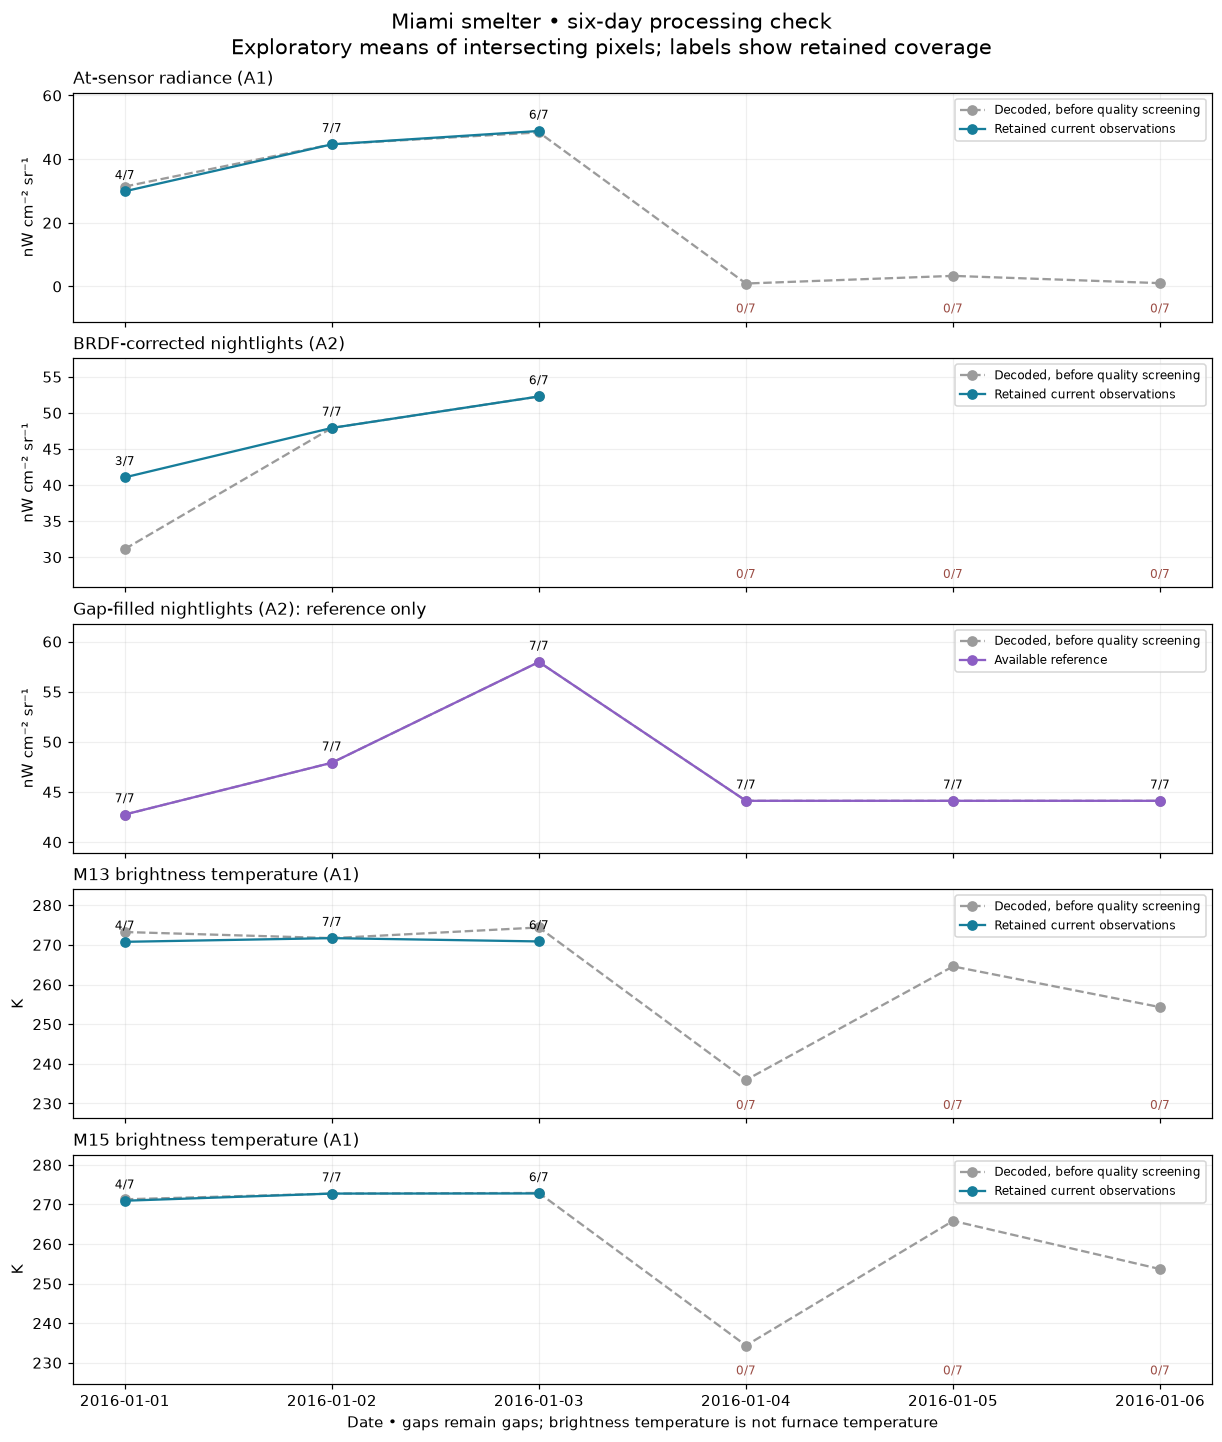

In [9]:
fig = plot_preview(daily)
fig

## 7. Save the six-day outputs

Separate preview NetCDF cubes retain decoded values, screened/reference values, exclusion bitmasks, decoded cloud fields and spatial metadata. CSV files provide the per-pixel audit, per-date packing and daily coverage summaries. Raw Zarr and monthly archives remain unchanged. This workflow intentionally refuses ranges longer than six days until this processing stage has been reviewed.

In [10]:
output = export_preview(processed, audit, packing, daily)
print('Results:', output.resolve())
print(*sorted(path.name for path in output.iterdir()), sep=chr(10))
plt.close('all')

Results: C:\Users\zayed\OneDrive\Desktop\Earth-i\EI-Nightlights\outputs\miami_six_day_processing
VNP46A1_preview.nc
VNP46A2_preview.nc
daily_summary.csv
packing_by_date.csv
pixel_audit.csv
processing_report.json
six_day_comparison.png


## What this establishes and what remains

The sample validates decoding, explicit quality screening, A1/A2 coordinate alignment and preservation of missing observations. Before full-archive processing, review the screening choices and confirm the AOI against the actual smelter footprint. The small number of mixed pixels limits attribution to the facility. No outlier clipping, interpolation, smoothing, product substitution or activity classification is performed.

**Sources checked against native per-scene metadata:**

- [NASA Collection 2 A1 specification](https://ladsweb.modaps.eosdis.nasa.gov/filespec/VIIRS/2/VNP46A1_v2.0.fs)
- [NASA Collection 2 A2 specification](https://ladsweb.modaps.eosdis.nasa.gov/filespec/VIIRS/2/VNP46A2_v2.0.fs)
- [NASA Black Marble Collection 2 user guide](https://viirsland.gsfc.nasa.gov/PDF/BlackMarbleUserGuide_Collection2.0.pdf)